In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader, TensorDataset, random_split, Subset
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import joblib
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Using device: cuda


In [2]:
import pandas as pd
import joblib
import os
from sklearn.preprocessing import MinMaxScaler

# --- Load the pre-generated mock data (AI_Model/tests/mock_data_month.csv) ---
# Produced by AI_Model/tests/data_gen.py: 30 days x 1440 minutes, single generic
# 70+ resident profile, normal routine only (no anomalies baked into the file).
DATA_FILENAME = 'sample_data/mock_data_month.csv'

if not os.path.exists(DATA_FILENAME):
    try:
        from google.colab import files
        print(f"'{DATA_FILENAME}' not found next to the notebook -- please upload it "
              f"(from AI_Model/tests/mock_data_month.csv on your machine).")
        uploaded = files.upload()
        assert DATA_FILENAME in uploaded, f"Expected an upload named '{DATA_FILENAME}'"
    except ImportError:
        raise FileNotFoundError(
            f"'{DATA_FILENAME}' not found. Place it next to this notebook, or run in "
            f"Colab to be prompted for an upload."
        )

df_clean = pd.read_csv(DATA_FILENAME)
print(f"✅ Data loaded, shape: {df_clean.shape}")

# Sanity check: meds + door -- both used to be stuck at ~0% location occupancy
# in this notebook's old inline generator; confirm the file doesn't have that problem.
_s4 = df_clean['sensor_4']
_rising = ((_s4 == 1) & (_s4.shift(1, fill_value=0) == 0)).sum()
n_days = len(df_clean) // 1440
print(f"💊 Total meds events (rising edges) in {n_days} days: {_rising} (~{_rising/n_days:.1f}/day)")
print(f"🚪 Door occupancy (time actually outside): {100 * df_clean['location_0'].mean():.1f}% of minutes")
print(f"💊 Medications occupancy: {100 * df_clean['location_4'].mean():.2f}% of minutes")

scaler = MinMaxScaler()

scaled_values = scaler.fit_transform(df_clean)
df_final_scaled = pd.DataFrame(scaled_values, columns=df_clean.columns)

joblib.dump(scaler, 'scaler.pkl')
print("✅ Data normalized and scaler.pkl saved successfully!")

✅ Data loaded, shape: (43200, 18)
💊 Total meds events (rising edges) in 30 days: 60 (~2.0/day)
🚪 Door occupancy (time actually outside): 13.3% of minutes
💊 Medications occupancy: 0.19% of minutes
✅ Data normalized and scaler.pkl saved successfully!


In [3]:
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

def create_sequences(data, window_size=360):
    """
    Creates rolling window sequences for LSTM.
    Input: DataFrame or 2D Numpy Array
    Output: 3D Numpy Array [Samples, Time_Steps, Features]
    """
    if hasattr(data, 'values'):
        data = data.values

    sequences = []
    for i in range(len(data) - window_size + 1):
        window = data[i : i + window_size]
        sequences.append(window)

    return np.array(sequences)

# Window size: 6 hours = 360 minutes
WINDOW_SIZE = 360

X_train = create_sequences(df_final_scaled, window_size=WINDOW_SIZE)

# Convert to PyTorch tensors (Float32). Kept on CPU initially to avoid memory overflow.
X_tensor = torch.tensor(X_train, dtype=torch.float32)

# Create DataLoader. For an Autoencoder, target (Y) is identical to input (X).
batch_size = 64
train_dataset = TensorDataset(X_tensor, X_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

print(f"✅ Sequence creation completed!")
print(f"📊 Final tensor shape: {X_tensor.shape}")
print(f"📦 Number of training batches: {len(train_loader)}")

✅ Sequence creation completed!
📊 Final tensor shape: torch.Size([42841, 360, 18])
📦 Number of training batches: 670


In [4]:
import torch
import torch.nn as nn

class Encoder(nn.Module):
    def __init__(self, seq_len, n_features, embedding_dim=64):
        super(Encoder, self).__init__()
        self.seq_len, self.n_features = seq_len, n_features
        self.embedding_dim, self.hidden_dim = embedding_dim, 2 * embedding_dim

        self.rnn1 = nn.LSTM(input_size=n_features, hidden_size=self.hidden_dim, num_layers=1, batch_first=True)
        # Dropout added to prevent overfitting
        self.dropout = nn.Dropout(0.2)
        self.rnn2 = nn.LSTM(input_size=self.hidden_dim, hidden_size=embedding_dim, num_layers=1, batch_first=True)

    def forward(self, x):
        x, _ = self.rnn1(x)
        x = self.dropout(x)
        x, (hidden_n, _) = self.rnn2(x)
        return hidden_n.reshape((x.shape[0], 1, self.embedding_dim))

class Decoder(nn.Module):
    # Signature must exactly match ai_handler.py on the server
    def __init__(self, seq_len, embedding_dim=64, n_features=18):
        super(Decoder, self).__init__()
        self.seq_len, self.embedding_dim = seq_len, embedding_dim
        self.hidden_dim, self.n_features = 2 * embedding_dim, n_features

        self.rnn1 = nn.LSTM(input_size=embedding_dim, hidden_size=embedding_dim, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(0.2)
        self.rnn2 = nn.LSTM(input_size=embedding_dim, hidden_size=self.hidden_dim, num_layers=1, batch_first=True)

        self.output_layer = nn.Linear(self.hidden_dim, n_features)
        # Essential: bounds the output between 0 and 1 for normalized features
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = x.repeat(1, self.seq_len, 1)
        x, _ = self.rnn1(x)
        x = self.dropout(x)
        x, _ = self.rnn2(x)
        x = self.output_layer(x)
        return self.sigmoid(x)

class LSTMAnomalyDetector(nn.Module):
    def __init__(self, seq_len, n_features, embedding_dim=64):
        super(LSTMAnomalyDetector, self).__init__()
        self.encoder = Encoder(seq_len, n_features, embedding_dim)
        self.decoder = Decoder(seq_len, embedding_dim, n_features)

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

# Columns 0:7 are the sparse binary sensor_* event flags; 7:18 is location one-hot + time.
SENSOR_SLICE = slice(0, 7)

def weighted_reconstruction_loss(prediction, target, positive_weight):
    """The original single MSE mean over all 18 columns, with the squared error on
    positive sensor targets (cols 0:7, target == 1) scaled by positive_weight.

    Keeping one mean over all 18 columns (not a separate mean per block) preserves the
    original relative weighting between the 7 sensor columns and the other 11 -- summing
    two block means would give each block equal total weight regardless of width.
    positive_weight=1.0 reproduces nn.MSELoss() exactly.
    """
    weight = torch.ones_like(target)
    sensor_target = target[..., SENSOR_SLICE]
    weight[..., SENSOR_SLICE] = torch.where(sensor_target == 1, positive_weight, 1.0)
    return (weight * (prediction - target) ** 2).mean()


def train_model(model, train_loader, val_loader, positive_weight, n_epochs=100):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    positive_weight = positive_weight.to(device) if torch.is_tensor(positive_weight) else positive_weight

    # Added weight_decay for L2 regularization
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

    history = {'train': [], 'val': [], 'train_sensor_mse': [], 'train_other_mse': [],
               'val_sensor_mse': [], 'val_other_mse': []}
    best_loss = float('inf')
    patience = 10
    counter = 0

    for epoch in range(n_epochs):
        model.train()
        train_losses, train_sensor_mses, train_other_mses = [], [], []
        for x_batch, _ in train_loader:
            x_batch = x_batch.to(device)
            optimizer.zero_grad()

            output = model(x_batch)
            loss = weighted_reconstruction_loss(output, x_batch, positive_weight)

            loss.backward()

            # Gradient Clipping to prevent exploding gradients in LSTM
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()
            train_losses.append(loss.item())

            # Detached diagnostics only -- plain unweighted MSE per block, never part of
            # the objective. Lets us see whether positive_weight is actually moving the
            # sensor columns, since the single weighted total on its own won't show that.
            with torch.no_grad():
                train_sensor_mses.append(nn.functional.mse_loss(output[..., 0:7], x_batch[..., 0:7]).item())
                train_other_mses.append(nn.functional.mse_loss(output[..., 7:18], x_batch[..., 7:18]).item())

        model.eval()
        val_losses, val_sensor_mses, val_other_mses = [], [], []
        with torch.no_grad():
            for x_val, _ in val_loader:
                x_val = x_val.to(device)
                output = model(x_val)
                loss = weighted_reconstruction_loss(output, x_val, positive_weight)
                val_losses.append(loss.item())
                val_sensor_mses.append(nn.functional.mse_loss(output[..., 0:7], x_val[..., 0:7]).item())
                val_other_mses.append(nn.functional.mse_loss(output[..., 7:18], x_val[..., 7:18]).item())

        train_loss = np.mean(train_losses)
        val_loss = np.mean(val_losses)
        history['train'].append(train_loss)
        history['val'].append(val_loss)
        history['train_sensor_mse'].append(np.mean(train_sensor_mses))
        history['train_other_mse'].append(np.mean(train_other_mses))
        history['val_sensor_mse'].append(np.mean(val_sensor_mses))
        history['val_other_mse'].append(np.mean(val_other_mses))

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'Epoch {epoch+1}: Train Loss {train_loss:.6f} (sensor_mse {history["train_sensor_mse"][-1]:.6f}, '
                  f'other_mse {history["train_other_mse"][-1]:.6f}) | '
                  f'Val Loss {val_loss:.6f} (sensor_mse {history["val_sensor_mse"][-1]:.6f}, '
                  f'other_mse {history["val_other_mse"][-1]:.6f})')

        # Save the best model based on validation loss (the same weighted objective the
        # model is trained on -- early stopping must track what's actually optimized)
        if val_loss < best_loss:
            best_loss = val_loss
            torch.save(model.state_dict(), 'best_safe_house_model_weighted.pth')
            counter = 0
        else:
            counter += 1
            if counter >= patience:
                print(f"🛑 Early Stopping triggered at epoch {epoch+1}")
                break

    return history


Epoch 1: Train Loss 0.166623 (sensor_mse 0.085218, other_mse 0.109939) | Val Loss 0.161006 (sensor_mse 0.083094, other_mse 0.105815)
Epoch 5: Train Loss 0.116106 (sensor_mse 0.086621, other_mse 0.057741) | Val Loss 0.110461 (sensor_mse 0.086285, other_mse 0.051563)
Epoch 10: Train Loss 0.096258 (sensor_mse 0.086196, other_mse 0.036290) | Val Loss 0.104682 (sensor_mse 0.087318, other_mse 0.037124)
Epoch 15: Train Loss 0.084650 (sensor_mse 0.085098, other_mse 0.026923) | Val Loss 0.106401 (sensor_mse 0.088889, other_mse 0.034054)
Epoch 20: Train Loss 0.080922 (sensor_mse 0.084060, other_mse 0.025670) | Val Loss 0.111275 (sensor_mse 0.090004, other_mse 0.037696)
🛑 Early Stopping triggered at epoch 21


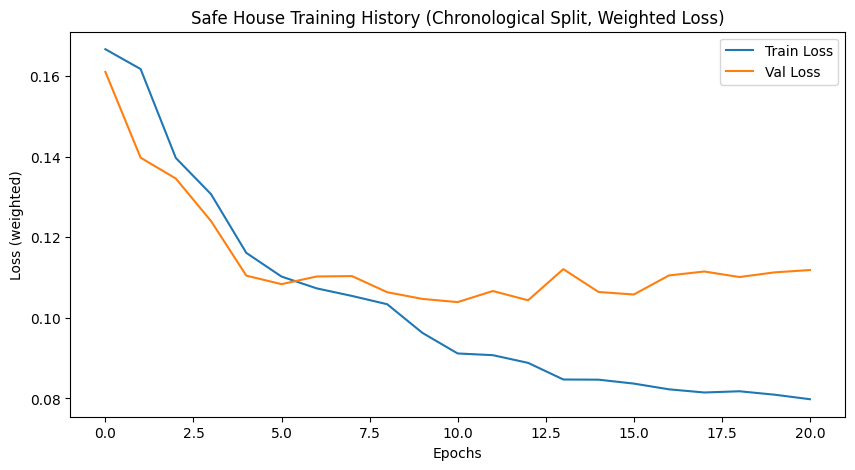

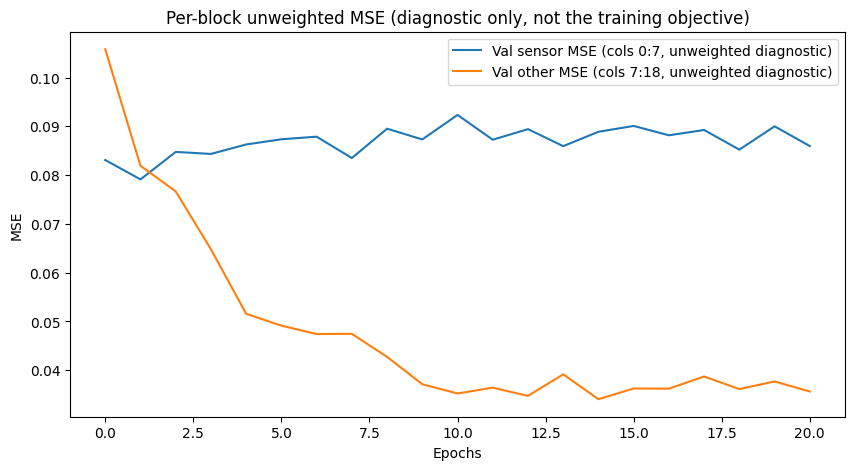

In [14]:
SEQ_LEN = 360
N_FEATURES = 18
EMBEDDING_DIM = 64

# Critical fix: Chronological split instead of random split
dataset_size = len(train_dataset)
train_size = int(0.8 * dataset_size)

# Leave a gap of SEQ_LEN between train and validation to prevent data leakage
# due to overlapping windows (stride=1)
train_indices = list(range(0, train_size))
val_indices = list(range(train_size + SEQ_LEN, dataset_size))

train_sub = Subset(train_dataset, train_indices)
val_sub = Subset(train_dataset, val_indices)

# shuffle=True is safe and recommended for train_loader now because the sets are completely isolated
train_loader = DataLoader(train_sub, batch_size=64, shuffle=True)
val_loader = DataLoader(val_sub, batch_size=64, shuffle=False)

model = LSTMAnomalyDetector(SEQ_LEN, N_FEATURES, EMBEDDING_DIM)

# Asymmetric weight on the squared error for POSITIVE sensor targets (cols 0:7) only.
# Sensor events are extremely sparse (0.14%-1.06% positive per channel -- see notebook
# header), and plain MSE collapses those channels to near-zero. A single scalar can't
# lift every channel equally (Meds needs ~719, Living Room only ~94); start with a
# scalar probe and move to a per-channel tensor for whichever channels stay collapsed --
# see verification section for how to check.
#
# Scalar form:
POSITIVE_WEIGHT = 100.0
positive_weight = torch.tensor(POSITIVE_WEIGHT)

# Per-channel form (order: Door, Kitchen, Bathroom, Toilet, Meds, Bedroom, LivingRm).
# Swap in if the scalar leaves some channels collapsed -- no other code changes needed,
# this just broadcasts differently inside weighted_reconstruction_loss.
# positive_weight = torch.tensor([634., 299., 539., 255., 719., 224., 94.])

history = train_model(model, train_loader, val_loader, positive_weight, n_epochs=50)

plt.figure(figsize=(10, 5))
plt.plot(history['train'], label='Train Loss')
plt.plot(history['val'], label='Val Loss')
plt.title('Safe House Training History (Chronological Split, Weighted Loss)')
plt.xlabel('Epochs')
plt.ylabel('Loss (weighted)')
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history['val_sensor_mse'], label='Val sensor MSE (cols 0:7, unweighted diagnostic)')
plt.plot(history['val_other_mse'], label='Val other MSE (cols 7:18, unweighted diagnostic)')
plt.title('Per-block unweighted MSE (diagnostic only, not the training objective)')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.legend()
plt.show()


In [15]:
import joblib
joblib.dump(scaler, 'scaler.pkl')
print("Scaler saved!")

# --- Verification helper: per-channel reconstruction check on a validation window ---
# Compares against the OLD (unweighted-MSE) checkpoint's measured baseline:
#   channel      recon max  @event mean  @quiet mean  ratio
#   Door           0.1515      0.0069       0.0042     1.65x
#   Kitchen        0.1492      0.0083       0.0058     1.43x
#   Bathroom       0.1537      0.0045       0.0041     1.08x
#   Toilet         0.1567      0.0063       0.0056     1.11x
#   Meds           0.1530      0.0041       0.0039     1.06x
#   Bedroom        0.1711      0.0111       0.0063     1.75x
#   LivingRm       0.1584      0.0170       0.0123     1.38x
# Pass = per-channel max clearly above baseline AND ratio clearly above baseline ratio
# (a ratio near 1.0 means the channel still emits a near-constant with no event timing
# learned at all -- that's the actual failure mode, not just a low max).
import numpy as np

SENSOR_NAMES = ['Door', 'Kitchen', 'Bathroom', 'Toilet', 'Meds', 'Bedroom', 'LivingRm']

def check_sensor_reconstruction(model, scaled_df, window_size=360, n_windows=20, tolerance=5):
    device = next(model.parameters()).device
    model.eval()
    data = scaled_df.values
    n = len(data)
    starts = np.linspace(0, n - window_size, n_windows).astype(int)
    A, R = [], []
    with torch.no_grad():
        for s in starts:
            w = data[s:s + window_size]
            r = model(torch.FloatTensor(w).unsqueeze(0).to(device)).squeeze(0).cpu().numpy()
            A.append(w)
            R.append(r)
    A = np.concatenate(A)
    R = np.concatenate(R)

    print(f"{'channel':<9} {'recon max':>10} {'@event':>10} {'@quiet':>10} {'ratio':>8}")
    for i, name in enumerate(SENSOR_NAMES):
        ev = A[:, i] == 1
        if ev.sum() == 0:
            print(f"{name:<9}  (no events in sample)")
            continue
        band = np.convolve(ev.astype(float), np.ones(2 * tolerance + 1), mode='same') > 0
        event_mean = R[band, i].mean()
        quiet_mean = R[~band, i].mean() if (~band).any() else float('nan')
        ratio = event_mean / max(quiet_mean, 1e-9)
        print(f"{name:<9} {R[:, i].max():10.4f} {event_mean:10.4f} {quiet_mean:10.4f} {ratio:8.2f}x")

check_sensor_reconstruction(model, df_final_scaled)


Scaler saved!
channel    recon max     @event     @quiet    ratio
Door          0.7770     0.4576     0.0854     5.36x
Kitchen       0.8400     0.5073     0.1337     3.79x
Bathroom      0.7440     0.3525     0.1165     3.03x
Toilet        0.7538     0.4017     0.2027     1.98x
Meds          0.7502     0.4826     0.0555     8.70x
Bedroom       0.8437     0.5757     0.2196     2.62x
LivingRm      0.8519     0.6127     0.3250     1.89x
